In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

In [19]:
df_meat = r"C:\Users\Ā\Documents\python_class\dataset\meatshops.gpkg"
meatshops = gpd.read_file(df_meat)

D:\miniconda_folder\envs\uisa_2026\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'meatshops.gpkg': 'notes' (default), 'notes_attachments'. Specify layer parameter to avoid this warning.
  result = read_func(


In [20]:
type(meatshops)

geopandas.geodataframe.GeoDataFrame

In [21]:
gpd.list_layers(df_meat)

,name,geometry_type
0,notes,Point Z
1,notes_attachments,NaN


In [22]:
meatshops = gpd.read_file(df_meat, layer="notes")

In [23]:
meatshops.head()

,uuid,color,title,note,timestamp,geometry
0,{2caa2aba-372a-444c-bb2b-1718c932abc9},#377eb8,Chendu chicken center,None,2026-08-01 05:10:06.029000+00:00,POINT Z (79.40947 13.6193 0)
1,{826fb641-6ce1-4b73-8fa1-74b128f2fbc9},#377eb8,Teja chicken center,None,2026-08-01 05:16:29.197000+00:00,POINT Z (79.40969 13.6195 0)
2,{a363af75-b8bd-443a-a181-77649082bbd1},#377eb8,Dhathri chicken center,None,2026-08-01 05:18:15.199000+00:00,POINT Z (79.40997 13.62107 0)
3,{37598a28-94c3-418a-90bb-a6efebf39be4},#377eb8,RK Suguna chicken center,None,2026-08-01 05:21:23.616000+00:00,POINT Z (79.40967 13.62204 0)
4,{04254b74-74d9-451f-9c85-0971ca76193d},#377eb8,Lalitha chicken center,None,2026-08-01 05:29:26.430000+00:00,POINT Z (79.40973 13.62273 0)


In [24]:
meatshops.shape

(105, 6)

In [25]:
meatshops.columns

Index(['uuid', 'color', 'title', 'note', 'timestamp', 'geometry'], dtype='str')

In [26]:
meatshops.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype              
---  ------     --------------  -----              
 0   uuid       105 non-null    str                
 1   color      105 non-null    str                
 2   title      105 non-null    str                
 3   note       0 non-null      object             
 4   timestamp  105 non-null    datetime64[ms, UTC]
 5   geometry   105 non-null    geometry           
dtypes: datetime64[ms, UTC](1), geometry(1), object(1), str(3)
memory usage: 5.1+ KB


In [27]:
meatshops.geometry.geom_type.value_counts()

Point    105
Name: count, dtype: int64

In [28]:
meatshops.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [29]:
meatshops.total_bounds

array([79.4094667 , 13.61718939, 79.45559471, 13.65619505])

<Axes: >

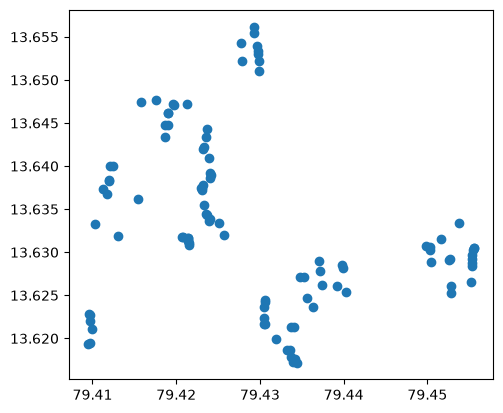

In [30]:
meatshops.plot()

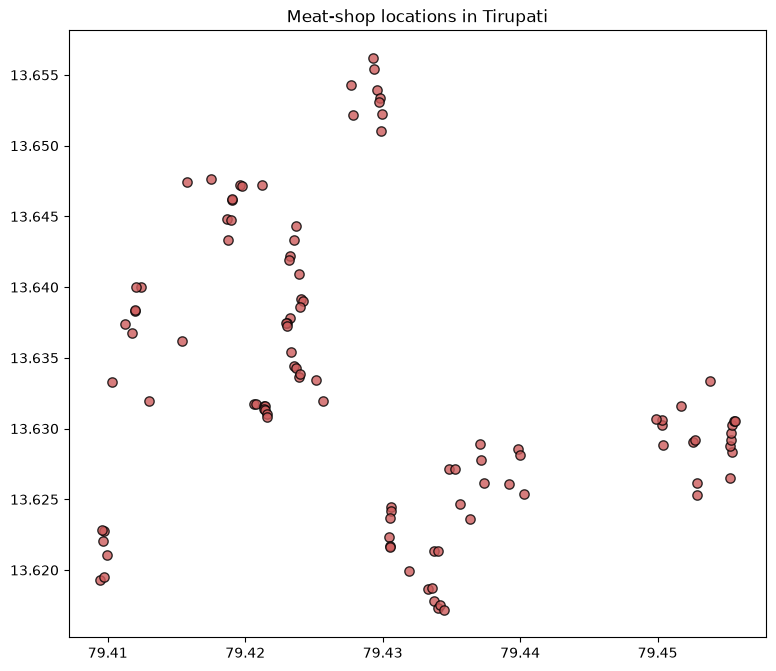

In [32]:
fig, ax = plt.subplots(figsize=(9, 8))

meatshops.plot(
    ax=ax,
    markersize=45,
    color= 'indianred',
    edgecolor= 'black',
    alpha=0.8
)

ax.set_title("Meat-shop locations in Tirupati")

plt.show()

In [18]:
type(df_meat)

str

In [33]:
meatshops_map = meatshops.to_crs(epsg=32644)

meatshops_map.crs

<Projected CRS: EPSG:32644>
Name: WGS 84 / UTM zone 44N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 78°E and 84°E, northern hemisphere between equator and 84°N, onshore and offshore. China. India. Kazakhstan. Kyrgyzstan. Nepal. Russian Federation. Sri Lanka.
- bounds: (78.0, 0.0, 84.0, 84.0)
Coordinate Operation:
- name: UTM zone 44N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

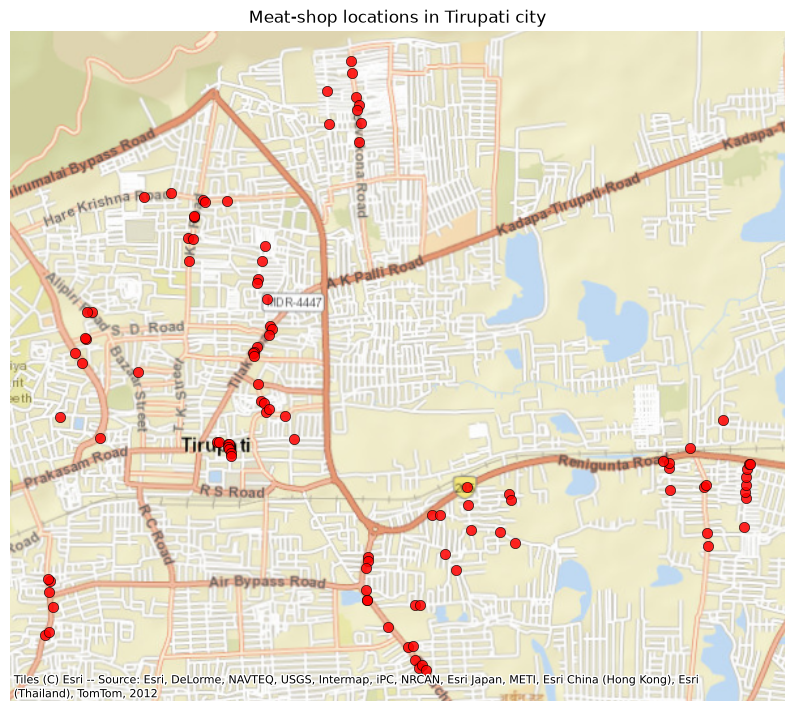

In [35]:
fig, ax = plt.subplots(figsize=(10, 9))

meatshops_map.plot(
    ax=ax,
    markersize=55,
    color="red",
    alpha=0.85,
    edgecolor="black",
    linewidth=0.5
)

ctx.add_basemap(
    ax,
    crs=meatshops_map.crs,
    source=ctx.providers.Esri.WorldStreetMap
)

ax.set_title("Meat-shop locations in Tirupati city")
ax.set_axis_off()

plt.show()

In [37]:
def add_north_arrow(ax, x=0.95, y=0.92):
    """Add a simple north arrow to a Matplotlib Axes."""

    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.12),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold",
        arrowprops=dict(
            facecolor="black",
            edgecolor="black",
            width=4,
            headwidth=12
        )
    )


In [38]:
def add_scale_bar(ax, length_m=1000):
    """Add a simple scale bar when map coordinates are in metres."""

    # 1. Find the current map extent
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    # 2. Choose a position slightly inside the lower-left corner
    x_start = xmin + 0.07 * (xmax - xmin)
    y_start = ymin + 0.07 * (ymax - ymin)

    # 3. Draw a horizontal line whose length equals length_m
    ax.plot(
        [x_start, x_start + length_m],
        [y_start, y_start],
        color="black",
        linewidth=4
    )

    # 4. Create a readable text label
    if length_m >= 1000:
        label = f"{length_m / 1000:g} km"
    else:
        label = f"{length_m:g} m"

    # 5. Place the label above the middle of the scale bar
    ax.text(
        x_start + length_m / 2,
        y_start + 0.015 * (ymax - ymin),
        label,
        ha="center",
        va="bottom",
        fontsize=10
    )

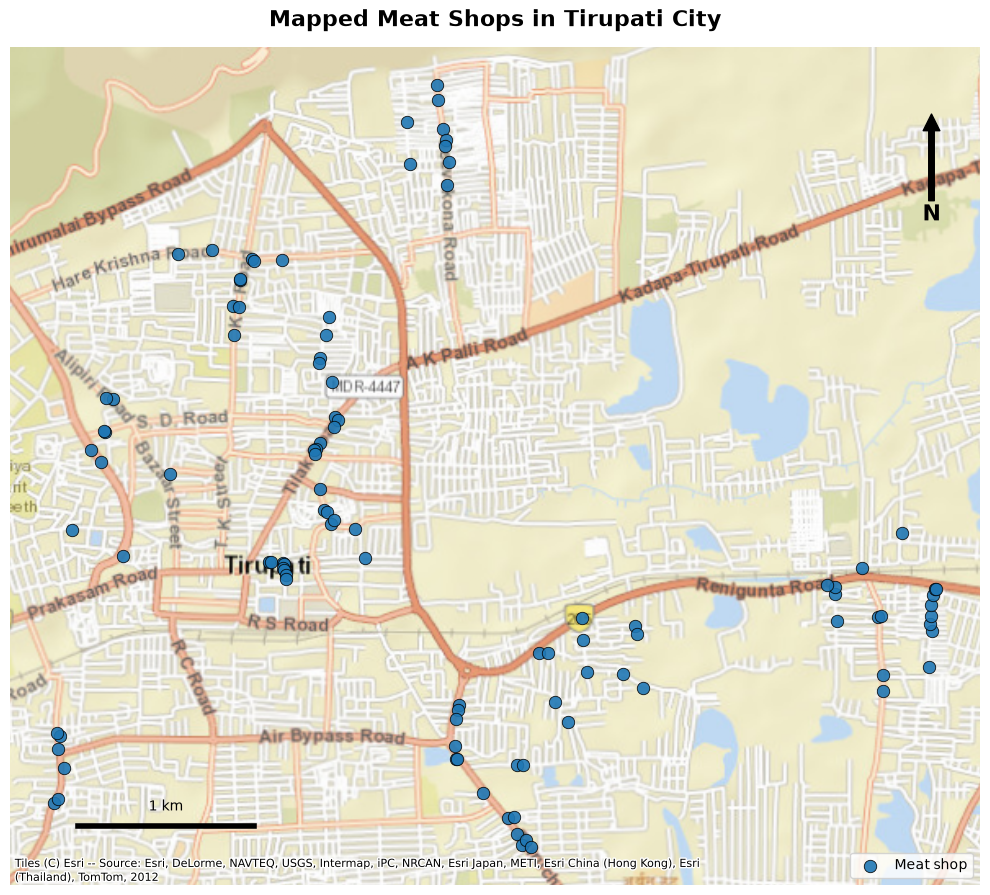

In [41]:
fig, ax = plt.subplots(figsize=(10, 10))

# 1. Plot the survey points
meatshops_map.plot(
    ax=ax,
    markersize=80,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.6,
    label="Meat shop"
)

# 2. Add OpenStreetMap underneath the survey layer
ctx.add_basemap(
    ax,
    crs=meatshops_map.crs,
    source=ctx.providers.Esri.WorldStreetMap
)

# 3. Explain what the map shows
ax.set_title(
    "Mapped Meat Shops in Tirupati City",
    fontsize=16,
    fontweight="bold",
    pad=15
)

# 4. Explain the point symbol
ax.legend(loc="lower right")

# 5. Add orientation and distance information
add_north_arrow(ax)
add_scale_bar(ax, length_m=1000)

# 6. Hide raw Easting/Northing axes for a cleaner final map
ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "output/tirupati_meatshops_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()